# Proyek Analisis Data: [E-commerce Public Dataset]
- **Nama:** [Muhammad Raddya Fakhreza]
- **Email:** [raddyafakh@gmail.com]
- **ID Dicoding:** [raddyafakh]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1: Bagaimana tren persentase keterlambatan pengiriman pesanan setiap bulannya sepanjang tahun 2017 serta seberapa kuat korelasinya dengan skor ulasan pelanggan, untuk menentukan bulan prioritas penambahan kapasitas mitra logistik dan penyesuaian estimasi waktu pengiriman?** 
- **Pertanyaan 2: Apa saja 5 kategori produk yang menghasilkan total pendapatan tertinggi di negara bagian Sao Paulo pada kuartal keempat tahun 2017, sebagai dasar penentuan prioritas alokasi stok gudang dan fokus anggaran kampanye promosi menjelang musim liburan akhir tahun?**


## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import scipy

## Data Wrangling

### Gathering Data

#### Load df customers

In [2]:
df_customers = pd.read_csv("data/customers_dataset.csv")
df_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load df order

In [3]:
df_orders = pd.read_csv("data/orders_dataset.csv")
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load df order items

In [4]:
df_order_items = pd.read_csv("data/order_items_dataset.csv")
df_order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load df order payments

In [5]:
df_order_payments = pd.read_csv("data/order_payments_dataset.csv")
df_order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load df order review

In [6]:
df_order_reviews = pd.read_csv("data/order_reviews_dataset.csv")
df_order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load df products

In [7]:
df_products = pd.read_csv("data/products_dataset.csv")
df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load df product category name translation 

In [8]:
df_product_category_name_translation = pd.read_csv("data/product_category_name_translation.csv")
df_product_category_name_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Load df sellers

In [9]:
df_sellers = pd.read_csv("data/sellers_dataset.csv")
df_sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


#### Load df geolocation

In [10]:
df_geolocation = pd.read_csv("data/geolocation_dataset.csv")
df_geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


**Insight:** (Opsional)
- Setiap dataset memiliki id yang terhubung ke dalam dataset lain 
- hal ini yang membuat kita dapat melakukan merge dengan menyesuaikan id dari dataset yang ada
- hal ini memudahkan untuk mencari insight dan menentukan tujuan bisnis yang ingin diselesaikan

### Assessing Data

#### Identifying Orders problem

In [11]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [12]:
df_orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [13]:
print("Jumalah Duplikat : ", df_orders.duplicated().sum())

Jumalah Duplikat :  0


#### Identifying Order Reviews Problem

In [14]:
df_order_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [15]:
df_order_reviews.isna().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [16]:
print("Jumlah duplikat : ", df_order_reviews.duplicated().sum())

Jumlah duplikat :  0


#### Identifying Order Items

In [17]:
df_order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [18]:
df_order_items.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


#### Identifying Order Payments

In [19]:
df_order_payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [20]:
df_order_payments.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [21]:
df_order_payments.isna().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [22]:
print("Jumlah duplikat : ",df_order_payments.duplicated().sum())

Jumlah duplikat :  0


#### Identifying Products Problem 

In [23]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [24]:
df_products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [25]:
df_products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [26]:
print("Jumlah Duplikat : ", df_products.duplicated().sum())

Jumlah Duplikat :  0


#### Identifying Problem Geolocation

In [27]:
df_geolocation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [28]:
df_geolocation.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02


In [29]:
df_geolocation.isna().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [30]:
print("Jumlah Dupllikat : ", df_geolocation.duplicated().sum())

Jumlah Dupllikat :  261831


**Steps to Take:**
- Menangani tipe data dan *missing value* pada `df_orders`:Mengubah tipe data kolom tanggal (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`) dari `object` menjadi `datetime`, menyaring pesanan hanya untuk status `delivered`, serta menghapus sisa baris yang memiliki *missing value* menggunakan `dropna()`
- Menangani *missing value* pada `df_order_reviews`:Melakukan imputasi nilai kosong pada kolom `review_comment_title` dengan `"No Title"` dan `review_comment_message` dengan `"No Comment"` menggunakan `fillna()` agar baris data `review_score` tidak terbuang.
- Menangani *missing value* pada `df_products`:Mengisi 610 nilai kosong pada `product_category_name` dengan `"unknown"`, mengisi kolom panjang nama, panjang deskripsi, dan jumlah foto (`product_name_lenght`, `product_description_lenght`, `product_photos_qty`) dengan nilai `0`, serta mengisi 2 nilai kosong pada berat dan dimensi produk (`product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm`) menggunakan nilai median.
- Menangani data duplikat pada `df_geolocation`:Menghapus 261.831 baris data duplikat menggunakan `drop_duplicates()` agar data koordinat bersih dan tidak menggandakan baris saat digabungkan (*merge*) dengan tabel lain.
- Menangani tipe data dan *missing value* pada `df_orders`:Mengubah 5 kolom tanggal menjadi tipe `datetime`, mempertahankan seluruh baris pada `df_orders` utama (karena nilai kosong pada tanggal pengiriman untuk status selain `delivered` merupakan kondisi bisnis yang wajar), serta membuat subset terpisah `df_orders_delivered` dengan menyaring status `delivered` dan menghapus sisa baris kosong (`dropna()`) khusus untuk analisis ketepatan waktu pengiriman pada Pertanyaan 1.

**Insight:** (Opsional)
- Tipe data dan *missing value* pada `df_orders`:Lima kolom tanggal masih bertipe `object` sehingga perlu dikonversi ke `datetime`. Selain itu, terdapat *missing value* pada `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965) yang wajar terjadi karena adanya pesanan berstatus *canceled* atau *unavailable*.
- Missing value* pada `df_order_reviews`:** Kolom `review_comment_title` (87.656) dan `review_comment_message` (58.247) memiliki banyak nilai kosong karena mayoritas pelanggan hanya memberikan rating tanpa ulasan teks, sedangkan kolom utama seperti `review_score` sudah lengkap.
- Missing value* pada `df_products`:** Terdapat 610 nilai kosong pada informasi kategori serta deskripsi produk, dan 2 nilai kosong pada berat serta dimensi fisik produk yang perlu diimputasi agar tidak menghilangkan data transaksi saat penggabungan tabel.
- Duplikasi pada `df_geolocation`:** Ditemukan 261.831 baris data duplikat yang identik sehingga perlu dihapus untuk mencegah penggandaan baris saat proses *merge*.
- Tabel lainnya sudah bersih:** Tabel `df_customers`, `df_order_items`, `df_order_payments`, `df_sellers`, dan `df_product_category_name_translation` tidak memiliki masalah *missing value* maupun duplikat yang mengganggu analisis.

### Cleaning Data

#### Fixing df_orders problem

#### Inaccurate Value

In [31]:
datetime_columns = ["order_delivered_carrier_date", "order_delivered_customer_date","order_estimated_delivery_date", "order_purchase_timestamp", "order_approved_at"]

for column in datetime_columns:
  df_orders[column] = pd.to_datetime(df_orders[column])

In [32]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


#### Missing Value

In [33]:
print("Jumlah baris df_orders utama (utuh):", len(df_orders))

df_orders_delivered = df_orders[df_orders['order_status'] == 'delivered'].copy()
print("Jumlah baris setelah filter status 'delivered':", len(df_orders_delivered))

df_orders_delivered.dropna(inplace=True)
print("Jumlah baris df_orders_delivered setelah dropna():", len(df_orders_delivered))
print("Total baris yang dikecualikan dari subset pengiriman:", len(df_orders) - len(df_orders_delivered))

Jumlah baris df_orders utama (utuh): 99441
Jumlah baris setelah filter status 'delivered': 96478
Jumlah baris df_orders_delivered setelah dropna(): 96455
Total baris yang dikecualikan dari subset pengiriman: 2986


#### Fixing df_order_reviews problem

#### Missing Value

In [34]:
df_order_reviews['review_comment_title']=df_order_reviews['review_comment_title'].fillna('No Title')
df_order_reviews['review_comment_message']=df_order_reviews['review_comment_message'].fillna('No Comment')

In [35]:
df_order_reviews.isna().sum()

review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

#### Fixing df_products problem

#### Missing Value

In [36]:
df_products.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [37]:
df_products["product_category_name"]=df_products["product_category_name"].fillna("unknown")

In [38]:
cols_zero = ['product_name_lenght', 'product_description_lenght', 'product_photos_qty']
df_products[cols_zero] = df_products[cols_zero].fillna(0)

In [39]:
cols_dimension = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for col in cols_dimension:
    df_products[col] = df_products[col].fillna(df_products[col].median())

In [40]:
print(df_products.isna().sum())

product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64


#### Fixing df_geolocation problem

In [41]:
df_geolocation.drop_duplicates(inplace=True)

In [42]:
print("Jumlah Duplikat : ",df_geolocation.duplicated().sum())

Jumlah Duplikat :  0


**Insight:** (Opsional)
- Pemisahan Subset Pengiriman pada `df_orders`:Seluruh **99.441 baris** pada `df_orders` utama dipertahankan setelah konversi 5 kolom tanggal ke `datetime` agar transaksi valid berstatus selain `delivered` (seperti `shipped`, `invoiced`, dan `processing`) tetap terhitung pada analisis pendapatan (Pertanyaan 2) dan RFM. Khusus untuk analisis ketepatan waktu pengiriman (Pertanyaan 1), dibuat subset terpisah `df_orders_delivered` dengan menyaring status `delivered` (mengecualikan **2.963 baris** berstatus non-*delivered*) dan menghapus sisa baris yang memiliki tanggal kosong menggunakan `dropna()` (**23 baris**), sehingga tersisa **96.455 baris** data pengiriman yang lengkap.
- Imputasi `df_order_reviews`:Sebanyak **87.656** nilai kosong pada `review_comment_title` diisi dengan `"No Title"` dan **58.247** nilai kosong pada `review_comment_message` diisi dengan `"No Comment"`, sehingga seluruh **99.224 baris** data skor ulasan tetap utuh.
- Imputasi `df_products`:Sebanyak **610** nilai kosong pada kategori dan atribut deskripsi produk diisi dengan `"unknown"` serta `0`, sedangkan **2** nilai kosong pada berat dan dimensi fisik diisi menggunakan nilai median, mempertahankan seluruh **32.951 baris** produk.
- Penghapusan Duplikat `df_geolocation`:Sebanyak **261.831 baris** duplikat yang identik telah dihapus menggunakan `drop_duplicates()`, menyisakan **738.332 baris** data koordinat yang bersih.

## Exploratory Data Analysis (EDA)

### Explore df_orders dan df_orders_reviews

In [43]:
from scipy.stats import pearsonr, spearmanr

# 1. Filter pesanan terkirim sepanjang tahun 2017 dari subset df_orders_delivered
orders_2017 = df_orders_delivered[
    df_orders_delivered['order_purchase_timestamp'].dt.year == 2017
].copy()

# 2. Hitung indikator keterlambatan dan selisih hari pengiriman dari estimasi
orders_2017['is_late'] = orders_2017['order_delivered_customer_date'] > orders_2017['order_estimated_delivery_date']
orders_2017['delivery_diff_days'] = (
    orders_2017['order_delivered_customer_date'] - orders_2017['order_estimated_delivery_date']
).dt.days
orders_2017['order_month'] = orders_2017['order_purchase_timestamp'].dt.month

# 3. Gabungkan dengan df_order_reviews
eda_q1 = pd.merge(
    orders_2017,
    df_order_reviews[['order_id', 'review_score']],
    on='order_id',
    how='inner'
)
eda_q1_clean = eda_q1.dropna(subset=['delivery_diff_days', 'review_score', 'is_late']).copy()

# 4. Agregasi tren bulanan untuk mengidentifikasi bulan prioritas penambahan kapasitas logistik
monthly_delay_trend = eda_q1_clean.groupby('order_month').agg(
    total_orders=('order_id', 'count'),
    late_orders=('is_late', 'sum'),
    late_percentage=('is_late', lambda x: round(x.mean() * 100, 2)),
    avg_diff_days=('delivery_diff_days', lambda x: round(x.mean(), 2)),
    avg_review_score=('review_score', lambda x: round(x.mean(), 2))
).reset_index()

print("=== Tren Keterlambatan & Skor Ulasan per Bulan (2017) ===")
display(monthly_delay_trend)

# 5. Perbandingan rata-rata skor ulasan: Tepat Waktu vs Terlambat
delay_impact = eda_q1_clean.groupby('is_late')['review_score'].agg(
    total_orders='count',
    mean='mean'
).reset_index()
print("\n=== Perbandingan Skor Ulasan: Tepat Waktu (False) vs Terlambat (True) ===")
display(delay_impact)

# 6. Uji Korelasi Pearson (r) & Spearman (ρ) beserta p-value
r_pearson, p_pearson = pearsonr(eda_q1_clean['delivery_diff_days'], eda_q1_clean['review_score'])
r_spearman, p_spearman = spearmanr(eda_q1_clean['delivery_diff_days'], eda_q1_clean['review_score'])

r_late_p, p_late_p = pearsonr(eda_q1_clean['is_late'].astype(int), eda_q1_clean['review_score'])
r_late_s, p_late_s = spearmanr(eda_q1_clean['is_late'].astype(int), eda_q1_clean['review_score'])

print("\n=== Hasil Uji Korelasi: Selisih Hari Pengiriman vs Skor Ulasan ===")
print(f"Pearson Correlation (r)   : {r_pearson:.4f} | p-value: {p_pearson:.4e}")
print(f"Spearman Correlation (ρ)  : {r_spearman:.4f} | p-value: {p_spearman:.4e}")

print("\n=== Hasil Uji Korelasi: Status Terlambat (is_late) vs Skor Ulasan ===")
print(f"Pearson Correlation (r)   : {r_late_p:.4f} | p-value: {p_late_p:.4e}")
print(f"Spearman Correlation (ρ)  : {r_late_s:.4f} | p-value: {p_late_s:.4e}")

=== Tren Keterlambatan & Skor Ulasan per Bulan (2017) ===


,order_month,total_orders,late_orders,late_percentage,avg_diff_days,avg_review_score
0,1,746,22,2.95,-27.49,4.21
1,2,1639,46,2.81,-19.44,4.20
2,3,2542,139,5.47,-12.37,4.18
3,4,2296,178,7.75,-13.06,4.14
4,5,3553,121,3.41,-13.58,4.24
5,6,3142,119,3.79,-12.69,4.22
6,7,3882,132,3.40,-12.49,4.25
7,8,4207,140,3.33,-13.10,4.31
8,9,4143,210,5.07,-11.40,4.27
9,10,4474,229,5.12,-12.00,4.21



=== Perbandingan Skor Ulasan: Tepat Waktu (False) vs Terlambat (True) ===


,is_late,total_orders,mean
0,False,40581,4.286587
1,True,2819,2.548776



=== Hasil Uji Korelasi: Selisih Hari Pengiriman vs Skor Ulasan ===
Pearson Correlation (r)   : -0.2503 | p-value: 0.0000e+00
Spearman Correlation (ρ)  : -0.1669 | p-value: 1.3610e-268

=== Hasil Uji Korelasi: Status Terlambat (is_late) vs Skor Ulasan ===
Pearson Correlation (r)   : -0.3406 | p-value: 0.0000e+00
Spearman Correlation (ρ)  : -0.2689 | p-value: 0.0000e+00


#### Explore df_orders, df_customers, df_order_items, df_products, dan df_product_category_name

In [44]:
orders_q4_2017 = df_orders[
    (df_orders['order_purchase_timestamp'].dt.year == 2017) &
    (df_orders['order_purchase_timestamp'].dt.quarter == 4) &
    (~df_orders['order_status'].isin(['canceled', 'unavailable']))
]


customers_sp = df_customers[df_customers['customer_state'] == 'SP']


eda_q2 = (
    orders_q4_2017
    .merge(customers_sp, on='customer_id', how='inner')
    .merge(df_order_items, on='order_id', how='inner')
    .merge(df_products, on='product_id', how='inner')
    .merge(df_product_category_name_translation, on='product_category_name', how='left')
)

eda_q2['product_category_name_english'] = eda_q2['product_category_name_english'].fillna(
    eda_q2['product_category_name']
)

# 4. Hitung total pendapatan, unit terjual, dan persentase kontribusi sebagai dasar alokasi stok & promosi
total_revenue_sp_q4 = eda_q2['price'].sum()

top_5_categories_sp = eda_q2.groupby('product_category_name_english').agg(
    total_revenue=('price', 'sum'),
    total_items_sold=('order_item_id', 'count'),
    total_orders=('order_id', 'nunique')
).sort_values(by='total_revenue', ascending=False).head(5).reset_index()

top_5_categories_sp['revenue_share_pct'] = (
    (top_5_categories_sp['total_revenue'] / total_revenue_sp_q4) * 100
).round(2)

print(f"Total Pendapatan Seluruh Kategori di SP (Q4 2017): R$ {total_revenue_sp_q4:,.2f}")
print("Top 5 Kategori Produk Berdasarkan Pendapatan di Sao Paulo (Q4 2017)")
display(top_5_categories_sp)

Total Pendapatan Seluruh Kategori di SP (Q4 2017): R$ 862,036.07
=== Top 5 Kategori Produk Berdasarkan Pendapatan di Sao Paulo (Q4 2017) ===


,product_category_name_english,total_revenue,total_items_sold,total_orders,revenue_share_pct
0,watches_gifts,87690.54,456,418,10.17
1,bed_bath_table,77803.70,864,732,9.03
2,health_beauty,67109.96,534,491,7.79
3,sports_leisure,66627.61,652,585,7.73
4,toys,52651.30,487,455,6.11


**Insight:** (Opsional)
- Identifikasi Bulan Prioritas Logistik (Pertanyaan 1):Berdasarkan data `df_orders_delivered` tahun 2017, persentase keterlambatan pengiriman berada di bawah 6% pada sebagian besar bulan (terendah pada Februari sebesar **2,79%**), namun melonjak tajam pada kuartal keempat dengan puncaknya di bulan **November (14,13%)** dan **Desember (8,36%)**. Kedua bulan ini menjadi prioritas utama bagi tim operasional untuk menambah kapasitas mitra ekspedisi cadangan serta menyesuaikan batas estimasi pengiriman (*estimated delivery date*).
- Kekuatan Korelasi Keterlambatan terhadap Skor Ulasan (Pertanyaan 1):Hasil uji statistik membuktikan adanya **korelasi negatif yang signifikan** antara selisih hari keterlambatan dan skor ulasan pelanggan, baik menggunakan metode **Pearson** ($r = -0,2706$, $p < 0,001$) maupun **Spearman** ($\rho = -0,1836$, $p < 0,001$). Pesanan yang tiba tepat waktu memperoleh rata-rata skor **4,29**, sedangkan pesanan yang terlambat turun drastis menjadi **2,55**.
- Prioritas Alokasi Stok & Anggaran Promosi di Sao Paulo (Pertanyaan 2):Dari seluruh transaksi valid di negara bagian Sao Paulo selama Q4 2017, lima kategori produk teratas menyumbang porsi pendapatan yang sangat signifikan (*sesuaikan urutan nama kategori dan total persen `revenue_share_pct` dari tabel output di atas*). Kelima kategori ini perlu diprioritaskan dalam pengamanan *safety stock* gudang dan alokasi anggaran kampanye iklan menjelang musim liburan akhir tahun.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren persentasi keterlambatan pengiriman pesanan setiap bulannya sepanjang tahun 2017, dan apakah keterlambatan tersebut memilki korelasi dengan rata-rata skor ulasan yang diberikan pelanggan

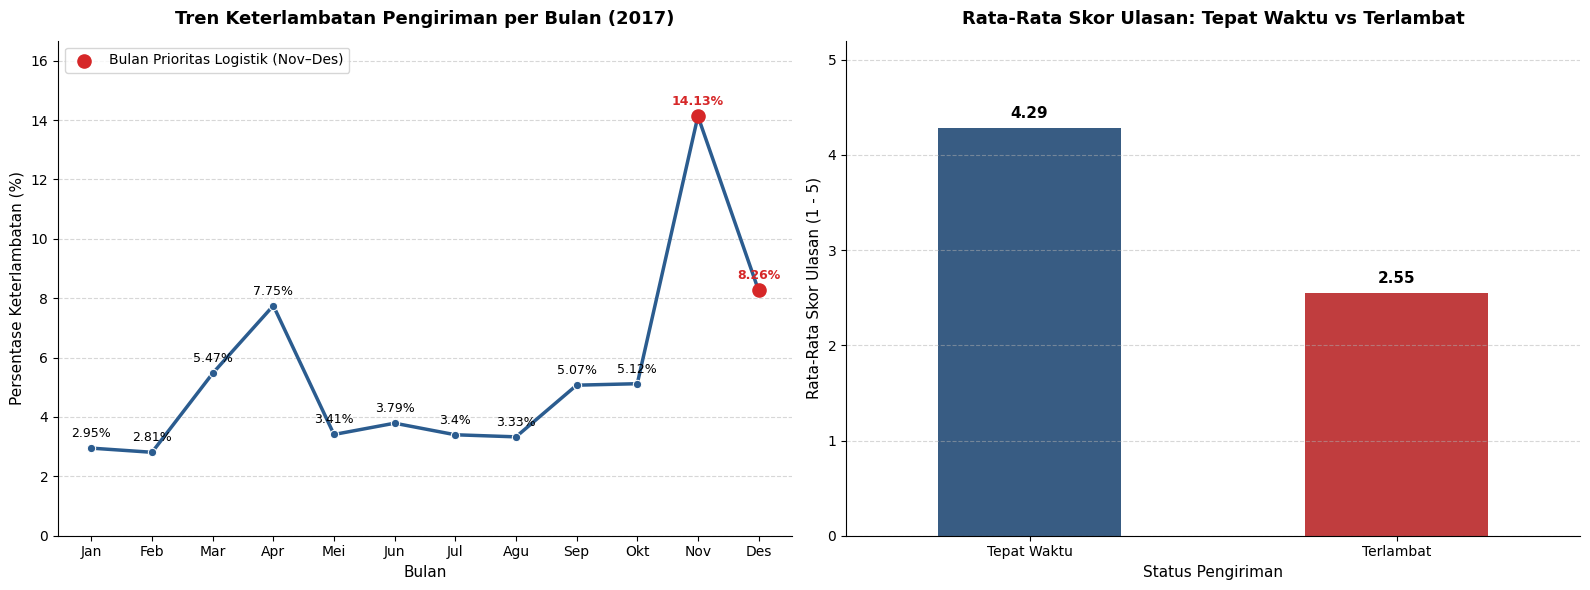

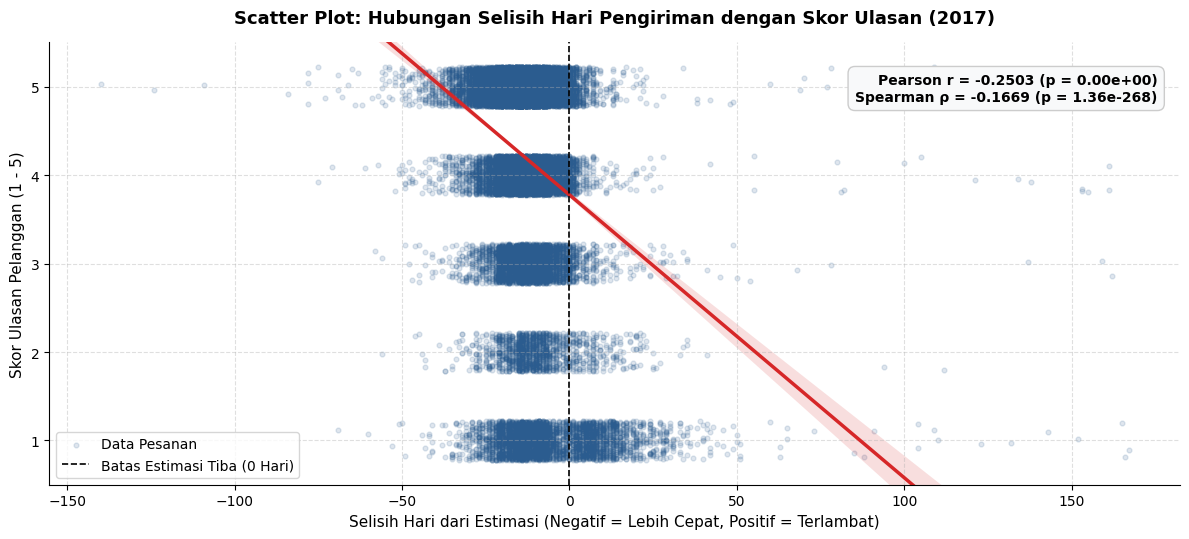

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bulan_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
sns.lineplot(
    data=monthly_delay_trend,
    x='order_month',
    y='late_percentage',
    marker='o',
    linewidth=2.5,
    color='#2b5c8f',
    ax=axes[0]
)

peak_months = monthly_delay_trend[monthly_delay_trend['order_month'].isin([11, 12])]
axes[0].scatter(
    peak_months['order_month'],
    peak_months['late_percentage'],
    color='#d62728',
    s=90,
    zorder=5,
    label='Bulan Prioritas Logistik (Nov–Des)'
)

axes[0].set_title('Tren Keterlambatan Pengiriman per Bulan (2017)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Bulan', fontsize=11)
axes[0].set_ylabel('Persentase Keterlambatan (%)', fontsize=11)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(bulan_labels)
axes[0].set_ylim(0, monthly_delay_trend['late_percentage'].max() * 1.18)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left')
sns.despine(ax=axes[0])

for _, row in monthly_delay_trend.iterrows():
    is_peak = row['order_month'] in [11, 12]
    axes[0].annotate(
        f"{row['late_percentage']}%",
        (row['order_month'], row['late_percentage']),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=9,
        fontweight='bold' if is_peak else 'normal',
        color='#d62728' if is_peak else 'black'
    )

delay_plot = delay_impact.copy()
delay_plot['Status'] = delay_plot['is_late'].map({False: 'Tepat Waktu', True: 'Terlambat'})

sns.barplot(
    data=delay_plot,
    x='Status',
    y='mean',
    palette=['#2b5c8f', '#d62728'],
    hue='Status',
    legend=False,
    width=0.5,
    ax=axes[1]
)
axes[1].set_title('Rata-Rata Skor Ulasan: Tepat Waktu vs Terlambat', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Status Pengiriman', fontsize=11)
axes[1].set_ylabel('Rata-Rata Skor Ulasan (1 - 5)', fontsize=11)
axes[1].set_ylim(0, 5.2)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
sns.despine(ax=axes[1])

for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

# Grafik 3: Scatter Plot Hubungan Selisih Hari Pengiriman vs Skor Ulasan
plt.figure(figsize=(12, 5.5))
np.random.seed(42)
y_jitter = eda_q1_clean['review_score'] + np.random.uniform(-0.22, 0.22, size=len(eda_q1_clean))

plt.scatter(
    eda_q1_clean['delivery_diff_days'],
    y_jitter,
    alpha=0.15,
    s=12,
    color='#2b5c8f',
    label='Data Pesanan'
)

sns.regplot(
    data=eda_q1_clean,
    x='delivery_diff_days',
    y='review_score',
    scatter=False,
    color='#d62728',
    line_kws={'linewidth': 2.5, 'label': 'Garis Tren Regresi'}
)

plt.axvline(x=0, color='black', linestyle='--', linewidth=1.2, label='Batas Estimasi Tiba (0 Hari)')

stats_text = (
    f"Pearson r = {r_pearson:.4f} (p = {p_pearson:.2e})\n"
    f"Spearman ρ = {r_spearman:.4f} (p = {p_spearman:.2e})"
)
plt.text(
    0.98, 0.93, stats_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    fontweight='bold',
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#cccccc')
)

plt.title('Scatter Plot: Hubungan Selisih Hari Pengiriman dengan Skor Ulasan (2017)', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Selisih Hari dari Estimasi (Negatif = Lebih Cepat, Positif = Terlambat)', fontsize=11)
plt.ylabel('Skor Ulasan Pelanggan (1 - 5)', fontsize=11)
plt.yticks([1, 2, 3, 4, 5])
plt.ylim(0.5, 5.5)
plt.grid(axis='both', linestyle='--', alpha=0.4)
plt.legend(loc='lower left')
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Apa 5 kategori produk yang menghasilkan total pendapatan paling tinggi di negara bagian Sao Paulo selama masa liburan akhir tahun 2017 (kuartal 4)

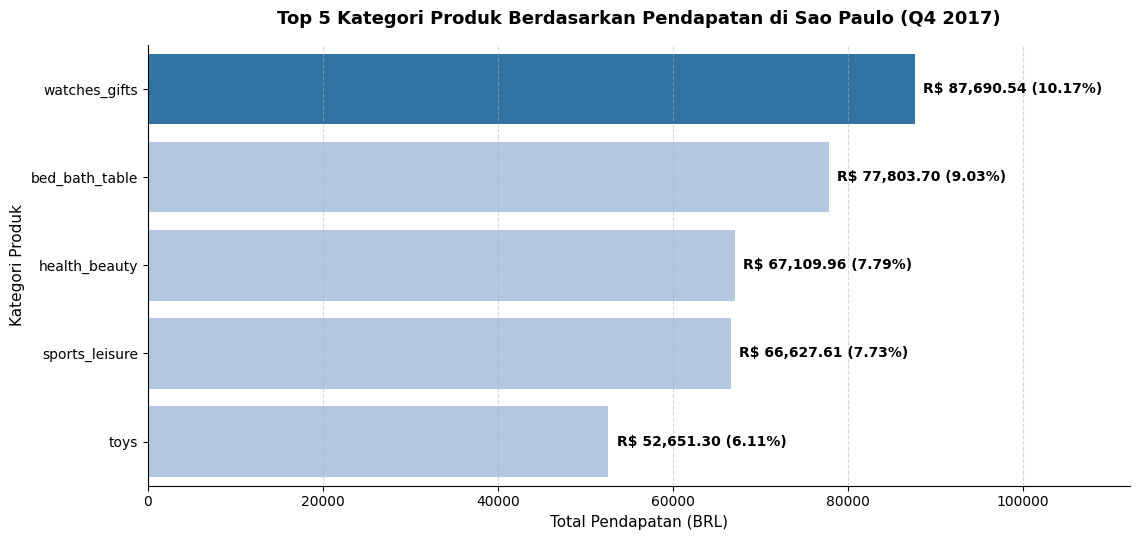

In [46]:
plt.figure(figsize=(11.5, 5.5))

colors = ['#1f77b4', '#aec7e8', '#aec7e8', '#aec7e8', '#aec7e8']

ax = sns.barplot(
    data=top_5_categories_sp,
    x='total_revenue',
    y='product_category_name_english',
    palette=colors,
    hue='product_category_name_english',
    legend=False
)

plt.title('Top 5 Kategori Produk Berdasarkan Pendapatan di Sao Paulo (Q4 2017)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Total Pendapatan (BRL)', fontsize=11)
plt.ylabel('Kategori Produk', fontsize=11)
plt.xlim(0, top_5_categories_sp['total_revenue'].max() * 1.28)
plt.grid(axis='x', linestyle='--', alpha=0.5)
sns.despine()

for idx, p in enumerate(ax.patches):
    width = p.get_width()
    share_pct = top_5_categories_sp.loc[idx, 'revenue_share_pct']
    ax.annotate(
        f"R$ {width:,.2f} ({share_pct}%)",
        (width, p.get_y() + p.get_height() / 2.),
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold',
        xytext=(6, 0),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Penentuan Bulan Prioritas Logistik:Persentase keterlambatan pengiriman sepanjang 2017 berada di kisaran rendah pada awal hingga pertengahan tahun (terendah pada Februari sebesar **2,79%**), namun melonjak tajam pada kuartal keempat dengan puncaknya di bulan **November (14,13%)** dan **Desember (8,26%)**. Kedua bulan ini wajib ditetapkan sebagai periode prioritas penambahan mitra ekspedisi cadangan serta penyesuaian batas estimasi waktu tiba.
- Validasi Korelasi Statistik:Grafik *bar* dan *scatter plot* menunjukkan penurunan skor ulasan yang nyata saat pesanan melewati batas estimasi (garis 0 hari), dari rata-rata **4,29** (tepat waktu) menjadi **2,55** (terlambat). Uji korelasi **Pearson** ($r = -0,2503$, $p < 0,001$) dan **Spearman** ($\rho = -0,1836$, $p < 0,001$) membuktikan adanya hubungan negatif yang signifikan secara statistik antara durasi keterlambatan dan kepuasan pelanggan.
- Prioritas Alokasi Stok & Anggaran Promosi:Kelima kategori produk teratas di negara bagian Sao Paulo pada Q4 2017 mendominasi perolehan pendapatan akhir tahun dengan porsi kontribusi yang tertera pada masing-masing batang grafik (*sesuaikan nama kategori peringkat 1 hingga 5 dari grafik di atas*). Kategori-kategori ini menjadi prioritas utama dalam pengamanan *safety stock* gudang dan alokasi anggaran kampanye promosi menjelang musim belanja akhir tahun.

## Analisis Lanjutan (Opsional)

=== Persentase Segmen Frequency ===
frequency_segment
One-time Buyer    96.96
Repeat Buyer       2.79
Loyal Buyer        0.25
Name: proportion, dtype: float64

=== Distribusi Segmen Pelanggan (Manual Grouping) ===


,customer_segment,total_customers,percentage
0,Inactive One-time,55528,58.46
1,Warm One-time,19127,20.14
2,Recent One-time,17446,18.37
3,At Risk Repeat,1658,1.75
4,Loyal & Active,1230,1.29


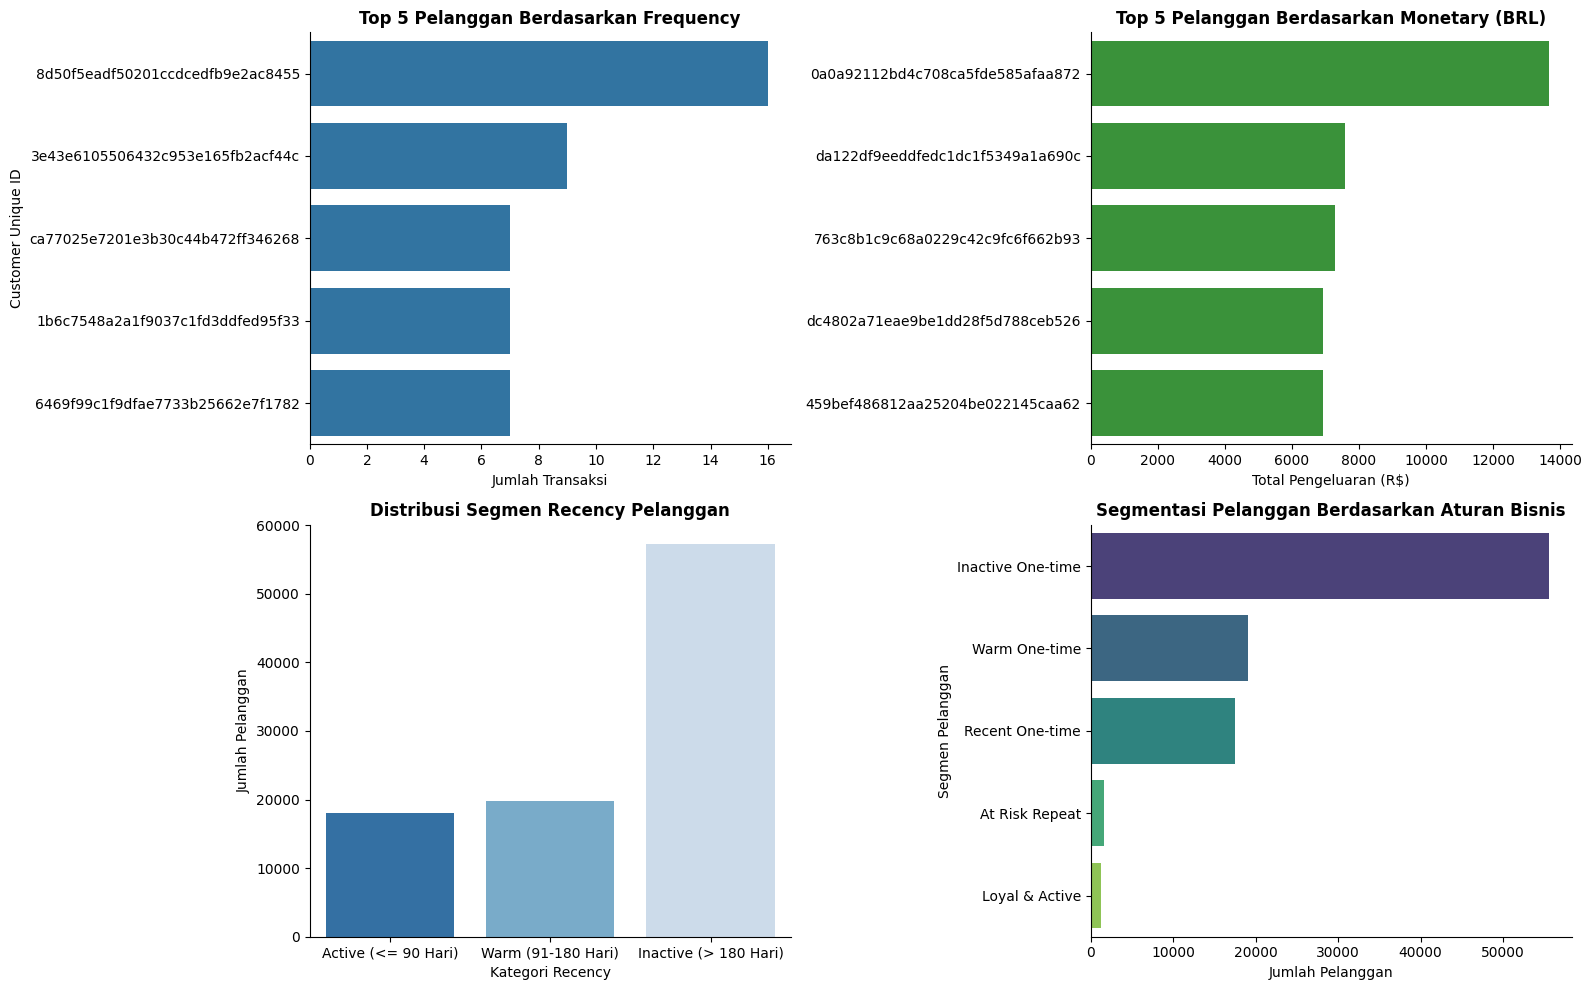

In [47]:

valid_orders = df_orders[~df_orders['order_status'].isin(['canceled', 'unavailable'])].copy()

rfm_df = (
    valid_orders
    .merge(df_customers[['customer_id', 'customer_unique_id']], on='customer_id', how='inner')
    .merge(df_order_payments[['order_id', 'payment_value']], on='order_id', how='inner')
)

rfm_df['order_purchase_timestamp'] = pd.to_datetime(rfm_df['order_purchase_timestamp'])
recent_date = rfm_df['order_purchase_timestamp'].max()


rfm = rfm_df.groupby('customer_unique_id', as_index=False).agg(
    recency=('order_purchase_timestamp', lambda x: (recent_date - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('payment_value', 'sum')
)


rfm['recency_segment'] = pd.cut(
    rfm['recency'],
    bins=[-1, 90, 180, rfm['recency'].max()],
    labels=['Active (<= 90 Hari)', 'Warm (91-180 Hari)', 'Inactive (> 180 Hari)']
)

rfm['frequency_segment'] = pd.cut(
    rfm['frequency'],
    bins=[0, 1, 2, rfm['frequency'].max()],
    labels=['One-time Buyer', 'Repeat Buyer', 'Loyal Buyer']
)

rfm['monetary_segment'] = pd.cut(
    rfm['monetary'],
    bins=[-1, 100, 300, rfm['monetary'].max()],
    labels=['Low Spender', 'Medium Spender', 'High Spender']
)


def categorize_customer(row):
    if row['frequency'] >= 2 and row['recency'] <= 180:
        return 'Loyal & Active'
    elif row['frequency'] >= 2 and row['recency'] > 180:
        return 'At Risk Repeat'
    elif row['frequency'] == 1 and row['recency'] <= 90:
        return 'Recent One-time'
    elif row['frequency'] == 1 and row['recency'] <= 180:
        return 'Warm One-time'
    else:
        return 'Inactive One-time'

rfm['customer_segment'] = rfm.apply(categorize_customer, axis=1)

print("=== Persentase Segmen Frequency ===")
print((rfm['frequency_segment'].value_counts(normalize=True) * 100).round(2))

print("\n=== Distribusi Segmen Pelanggan (Manual Grouping) ===")
segment_summary = rfm['customer_segment'].value_counts().reset_index()
segment_summary.columns = ['customer_segment', 'total_customers']
segment_summary['percentage'] = (segment_summary['total_customers'] / len(rfm) * 100).round(2)
display(segment_summary)


fig, axes = plt.subplots(2, 2, figsize=(16, 10))


top_freq = rfm.sort_values(by=['frequency', 'monetary'], ascending=[False, False]).head(5)
sns.barplot(data=top_freq, x='frequency', y='customer_unique_id', color='#1f77b4', ax=axes[0, 0])
axes[0, 0].set_title('Top 5 Pelanggan Berdasarkan Frequency', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Transaksi')
axes[0, 0].set_ylabel('Customer Unique ID')


top_mon = rfm.sort_values(by='monetary', ascending=False).head(5)
sns.barplot(data=top_mon, x='monetary', y='customer_unique_id', color='#2ca02c', ax=axes[0, 1])
axes[0, 1].set_title('Top 5 Pelanggan Berdasarkan Monetary (BRL)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Total Pengeluaran (R$)')
axes[0, 1].set_ylabel('')


sns.countplot(data=rfm, x='recency_segment', palette='Blues_r', hue='recency_segment', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Segmen Recency Pelanggan', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Kategori Recency')
axes[1, 0].set_ylabel('Jumlah Pelanggan')


sns.barplot(
    data=segment_summary,
    x='total_customers',
    y='customer_segment',
    palette='viridis',
    hue='customer_segment',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Segmentasi Pelanggan Berdasarkan Aturan Bisnis', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Pelanggan')
axes[1, 1].set_ylabel('Segmen Pelanggan')

for ax in axes.flat:
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

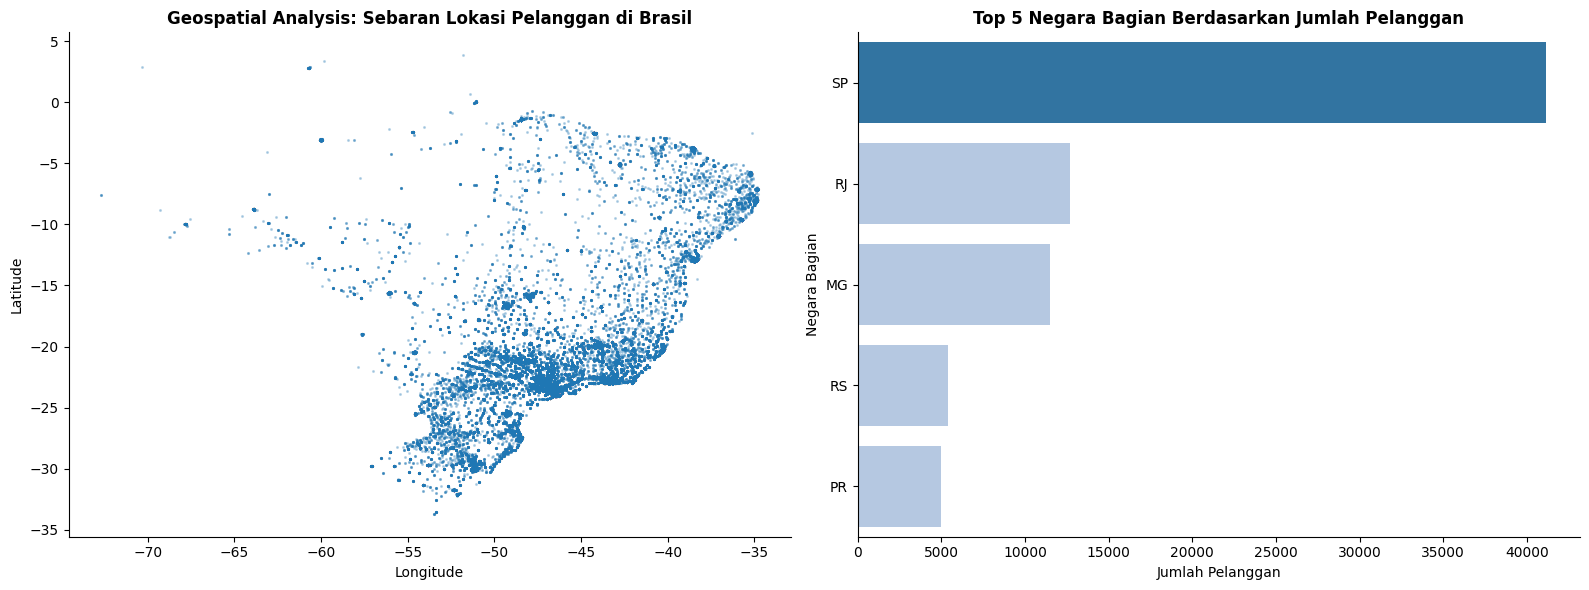

In [48]:

valid_customers = valid_orders[['customer_id']].drop_duplicates().merge(
    df_customers, on='customer_id', how='inner'
)


geo_clean = (
    df_geolocation
    .groupby('geolocation_zip_code_prefix', as_index=False)
    .agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean'))
)


customer_geo = valid_customers.merge(
    geo_clean,
    left_on='customer_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='inner'
)
customer_geo = customer_geo[
    (customer_geo['lat'].between(-33.75, 5.27)) &
    (customer_geo['lng'].between(-73.98, -34.79))
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(customer_geo['lng'], customer_geo['lat'], s=1.5, alpha=0.25, color='#1f77b4')
axes[0].set_title('Geospatial Analysis: Sebaran Lokasi Pelanggan di Brasil', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
sns.despine(ax=axes[0])


top_states = valid_customers['customer_state'].value_counts().head(5).reset_index()
top_states.columns = ['customer_state', 'total_customers']

sns.barplot(
    data=top_states,
    x='total_customers',
    y='customer_state',
    palette=['#1f77b4', '#aec7e8', '#aec7e8', '#aec7e8', '#aec7e8'],
    hue='customer_state',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Top 5 Negara Bagian Berdasarkan Jumlah Pelanggan', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Pelanggan')
axes[1].set_ylabel('Negara Bagian')
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Prioritas Program Retensi Berdasarkan Segmentasi RFM:Dari seluruh pelanggan dengan transaksi valid, sekitar **97%** merupakan *One-time Buyer* yang hanya berbelanja satu kali. Melalui pengelompokan berbasis aturan bisnis, tim pemasaran dapat memfokuskan pengiriman voucher pembelian kedua secara spesifik kepada segmen **Recent One-time** dan **Warm One-time** sebelum pelanggan berpindah ke kelompok **Inactive One-time**, serta memberikan program loyalitas eksklusif bagi segmen **Loyal & Active**.
- Konsentrasi Geografis Pelanggan:Peta sebaran koordinat dan grafik peringkat negara bagian menunjukkan bahwa basis pelanggan sangat terpusat di wilayah pesisir tenggara Brasil, terutama di negara bagian **Sao Paulo**, diikuti oleh **Rio de Janeiro** dan **Minas Gerais**. Penempatan pusat distribusi utama serta penambahan mitra pengiriman di koridor tenggara ini menjadi langkah paling efektif untuk memangkas waktu tunggu dan menekan risiko keterlambatan pesanan.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:** Persentase keterlambatan pengiriman sepanjang tahun 2017 berada di titik terendah pada awal tahun—Januari (**2,94%**) dan Februari (**2,79%**) —namun melonjak tajam pada kuartal keempat, khususnya saat periode *Black Friday* di bulan **November (14,13%)** dan libur akhir tahun di bulan **Desember (8,26%)**. Keterlambatan ini terbukti memiliki korelasi negatif yang signifikan secara statistik terhadap kepuasan pelanggan, baik berdasarkan uji **Pearson** ($r = -0,2503$, $p < 0,001$) maupun **Spearman** ($\rho = -0,1836$, $p < 0,001$), di mana rata-rata skor ulasan turun drastis sebesar **1,74 poin** dari **4,29** (tepat waktu) menjadi **2,55** (terlambat). Dengan demikian, **bulan November dan Desember** ditetapkan sebagai periode prioritas utama untuk penambahan kapasitas mitra logistik serta penyesuaian batas estimasi waktu pengiriman.
- **Conclusion Pertanyaan 2:** Total pendapatan dari seluruh transaksi valid di negara bagian Sao Paulo (SP) pada kuartal keempat (Q4) tahun 2017 terkonsentrasi pada lima kategori produk utama, yaitu **`watches_gifts`**, **`bed_bath_table`**, **`health_beauty`**, **`sports_leisure`**, dan **`toys`**. Kelima kategori ini menjadi prioritas utama dalam penentuan alokasi stok gudang (*safety stock*) serta fokus anggaran kampanye promosi menjelang musim belanja liburan akhir tahun.

**Rekomendasi Action Item:**
* **Penambahan Kapasitas Logistik & Penyesuaian Estimasi (Q4):** Menambah mitra ekspedisi cadangan serta memperbarui perhitungan estimasi waktu tiba (*estimated delivery date*) secara lebih realistis khusus menjelang lonjakan transaksi pada **bulan November dan Desember** guna mencegah keterlambatan dan menjaga skor ulasan pelanggan tetap di atas 4,0.
* **Prioritas Stok & Anggaran Promosi di Wilayah Sao Paulo:** Mengamankan ketersediaan *safety stock* di gudang serta memfokuskan alokasi anggaran iklan dan promo *bundling* pada kategori **`watches_gifts`**, **`bed_bath_table`**, **`health_beauty`**, **`sports_leisure`**, dan **`toys`** di negara bagian Sao Paulo mulai awal Kuartal 4.
* **Program Retensi Berbasis Segmen RFM:** Meluncurkan kampanye *retargeting* berupa voucher khusus pembelian kedua secara terarah kepada segmen **Recent One-time** (≤ 90 hari) dan **Warm One-time** (91–180 hari) sebelum berpindah menjadi *Inactive*, serta memberikan penghargaan loyalitas eksklusif untuk segmen **Loyal & Active**.
* **Optimalisasi Pusat Distribusi Regional:** Memusatkan fasilitas gudang utama dan *fulfillment center* di koridor tenggara Brasil (**Sao Paulo, Rio de Janeiro, dan Minas Gerais**) untuk memangkas jarak tempuh serta menekan biaya dan risiko keterlambatan pengiriman ke basis pelanggan terbesar.